In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [17]:
data = pd.read_csv("../other/ScreenTime vs MentalWellness.csv")
df = pd.DataFrame(data)
df.head()

,user_id,age,gender,occupation,work_mode,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week,mental_wellness_index_0_100,Unnamed: 15
0,U0001,33,Female,Employed,Remote,10.79,5.44,5.35,6.63,1,9.3,44.7,127,0.7,9.3,NaN
1,U0002,28,Female,Employed,In-person,7.40,0.37,7.03,8.05,3,5.7,78.0,74,2.1,56.2,NaN
2,U0003,35,Female,Employed,Hybrid,9.78,1.09,8.69,6.48,1,9.1,51.8,67,8.0,3.6,NaN
3,U0004,42,Male,Employed,Hybrid,11.13,0.56,10.57,6.89,1,10.0,37.0,0,5.7,0.0,NaN
4,U0005,28,Male,Student,Remote,13.22,4.09,9.13,5.79,1,10.0,38.5,143,10.1,0.0,NaN


In [18]:
df = df.drop(['user_id'], axis=1)
df.tail()

,age,gender,occupation,work_mode,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week,mental_wellness_index_0_100,Unnamed: 15
395,26,Female,Student,Remote,6.43,2.99,3.44,7.75,1,5.9,64.6,252,7.6,39.3,NaN
396,16,Male,Self-employed,Remote,9.59,5.44,4.15,5.57,1,10.0,47.4,99,7.0,3.5,NaN
397,40,Male,Student,Remote,8.72,2.36,6.36,7.56,1,9.4,57.3,193,10.1,6.6,NaN
398,29,Female,Retired,Hybrid,5.04,0.94,4.10,7.32,1,7.1,63.6,97,12.1,21.0,NaN
399,39,Female,Employed,Remote,8.86,3.82,5.04,6.55,1,10.0,41.4,88,9.8,8.4,NaN


In [19]:
df.describe()

,age,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week,mental_wellness_index_0_100,Unnamed: 15
count,400.00000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,0.0
mean,29.77750,9.024900,2.183075,6.841825,7.013175,1.397500,8.150500,54.306500,109.810000,7.905000,20.326750,NaN
std,7.46608,2.491058,1.931321,2.220896,0.852421,0.652348,2.094844,15.020054,70.007045,4.909632,20.376793,NaN
min,16.00000,1.000000,0.110000,0.890000,4.640000,1.000000,0.000000,20.600000,0.000000,0.000000,0.000000,NaN
25%,24.00000,7.372500,0.695000,5.460000,6.397500,1.000000,6.900000,43.600000,58.000000,4.575000,3.675000,NaN
50%,30.00000,9.090000,1.455000,6.700000,7.030000,1.000000,8.800000,51.750000,103.000000,7.750000,14.800000,NaN
75%,35.00000,10.495000,3.012500,8.417500,7.640000,2.000000,10.000000,63.000000,157.000000,11.025000,30.650000,NaN
max,60.00000,19.170000,12.040000,13.350000,9.740000,4.000000,10.000000,100.000000,372.000000,23.900000,97.000000,NaN


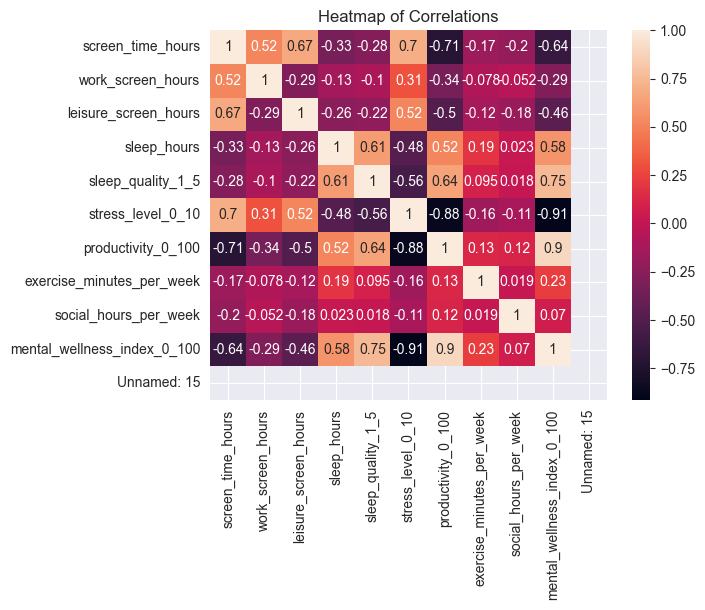

In [20]:
data_corr = df.drop(['age'], axis=1)
correlation_matrix = data_corr.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True)

plt.title('Heatmap of Correlations')
plt.show()

In [21]:
print("\n-----CORRELATION (top pairs)-----")

corr_unstack = correlation_matrix.unstack().reset_index()
corr_unstack.columns = ['var1', 'var2', 'value']
corr_unstack = corr_unstack[corr_unstack['var1'] != corr_unstack['var2']]
corr_unstack['abs_value'] = corr_unstack['value'].abs()
corr_unstack = corr_unstack.sort_values('abs_value', ascending=False).drop_duplicates(subset=['value'])
display(corr_unstack.head(12))


-----CORRELATION (top pairs)-----


,var1,var2,value,abs_value
104,mental_wellness_index_0_100,stress_level_0_10,-0.913818,0.913818
105,mental_wellness_index_0_100,productivity_0_100,0.902249,0.902249
61,stress_level_0_10,productivity_0_100,-0.879539,0.879539
103,mental_wellness_index_0_100,sleep_quality_1_5,0.750092,0.750092
6,screen_time_hours,productivity_0_100,-0.706537,0.706537
55,stress_level_0_10,screen_time_hours,0.697812,0.697812
2,screen_time_hours,leisure_screen_hours,0.669490,0.669490
50,sleep_quality_1_5,productivity_0_100,0.644802,0.644802
9,screen_time_hours,mental_wellness_index_0_100,-0.635943,0.635943
47,sleep_quality_1_5,sleep_hours,0.614381,0.614381


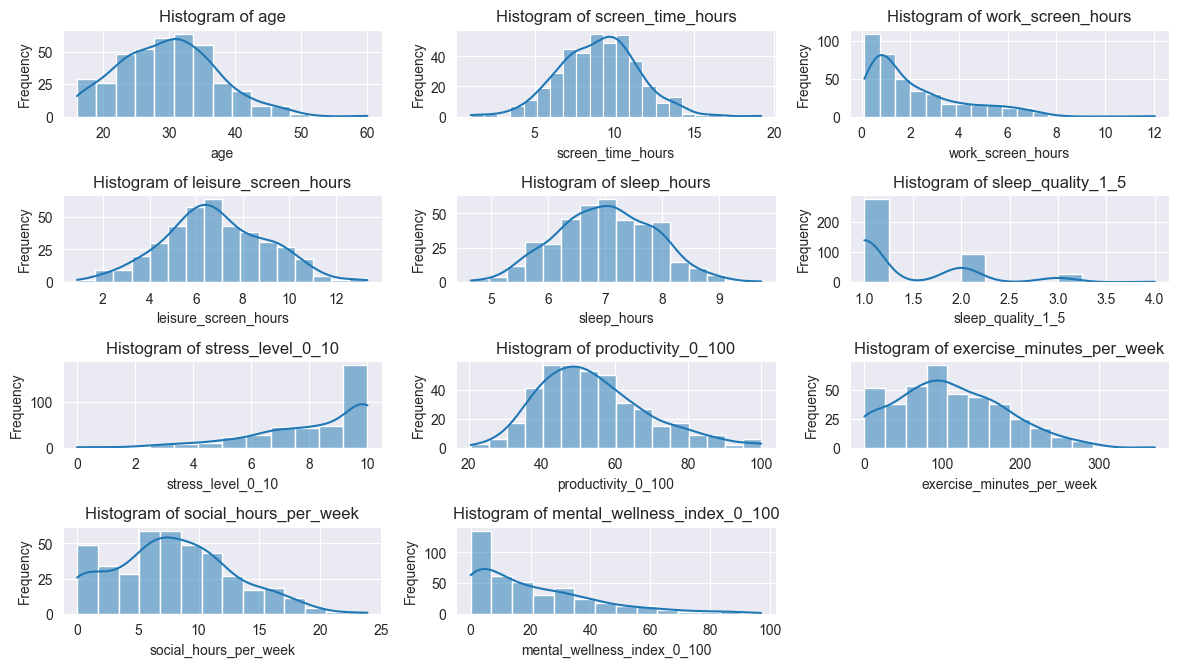

In [23]:
numeric_df = df.drop(['gender','occupation','work_mode'],axis=1)
plt.figure(figsize= (12,8))

for i, feature in enumerate(numeric_df.columns[:-1]):
    plt.subplot(5,3,i+1)
    sns.histplot(numeric_df[feature], kde= True)
    plt.title(f'Histogram of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()